# Example SIRDS model

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `0533e26bcabc`](https://github.com/OJWatson/metis/tree/0533e26bcabc75285429cda8181f1c8489e861ef).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("0533e26bcabc75285429cda8181f1c8489e861ef")


We use a stochastic SIRDS (Susceptible–Infected–Recovered–Dead–Susceptible)
compartmental model as a running example throughout the docs. The particulars
of the epidemic model are less important than its inputs and outputs: static
input parameters describe a simulation, and each run produces stochastic time
series of population counts.

People move from susceptible to infected, then either recover or die. Recovered
people can lose immunity and become susceptible again. The population is fixed
at 1,000, including people who have died.

| Input | Meaning |
|---|---|
| `I0` | Fraction of the population infected initially |
| `beta` | Transmission rate |
| `gamma` | Recovery rate |
| `omega` | Rate of loss of immunity |
| `mu` | Death rate among infected people |

## Code definition

The simulator is included in the installed package:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis.datasets.sirds import simulate_sirds

parameters = dict(I0=0.005, beta=0.4, gamma=0.1, omega=0.02, mu=0.01)
S, I, R, D = simulate_sirds(**parameters, N=1000, T=40, dt=1, seed=0)
print(f"{len(S)} time points, including the initial state")
print("Population conserved:", bool(np.all(S + I + R + D == 1000)))

41 time points, including the initial state
Population conserved: True


At each daily step, the simulator draws new infections and losses of immunity
from binomial distributions. A multinomial draw assigns each infected person
to recovery, death or remaining infected. For recovery, death and waning,
the step probability is $1-\exp(-\mathrm{rate}\times dt)$; infection also depends
on the current infected fraction. This is a discrete-time stochastic
simulation.

## Example realisations

Even with fixed input parameters, varying the random seed produces different
realisations. These are the differences a stochastic surrogate should learn
to reproduce.

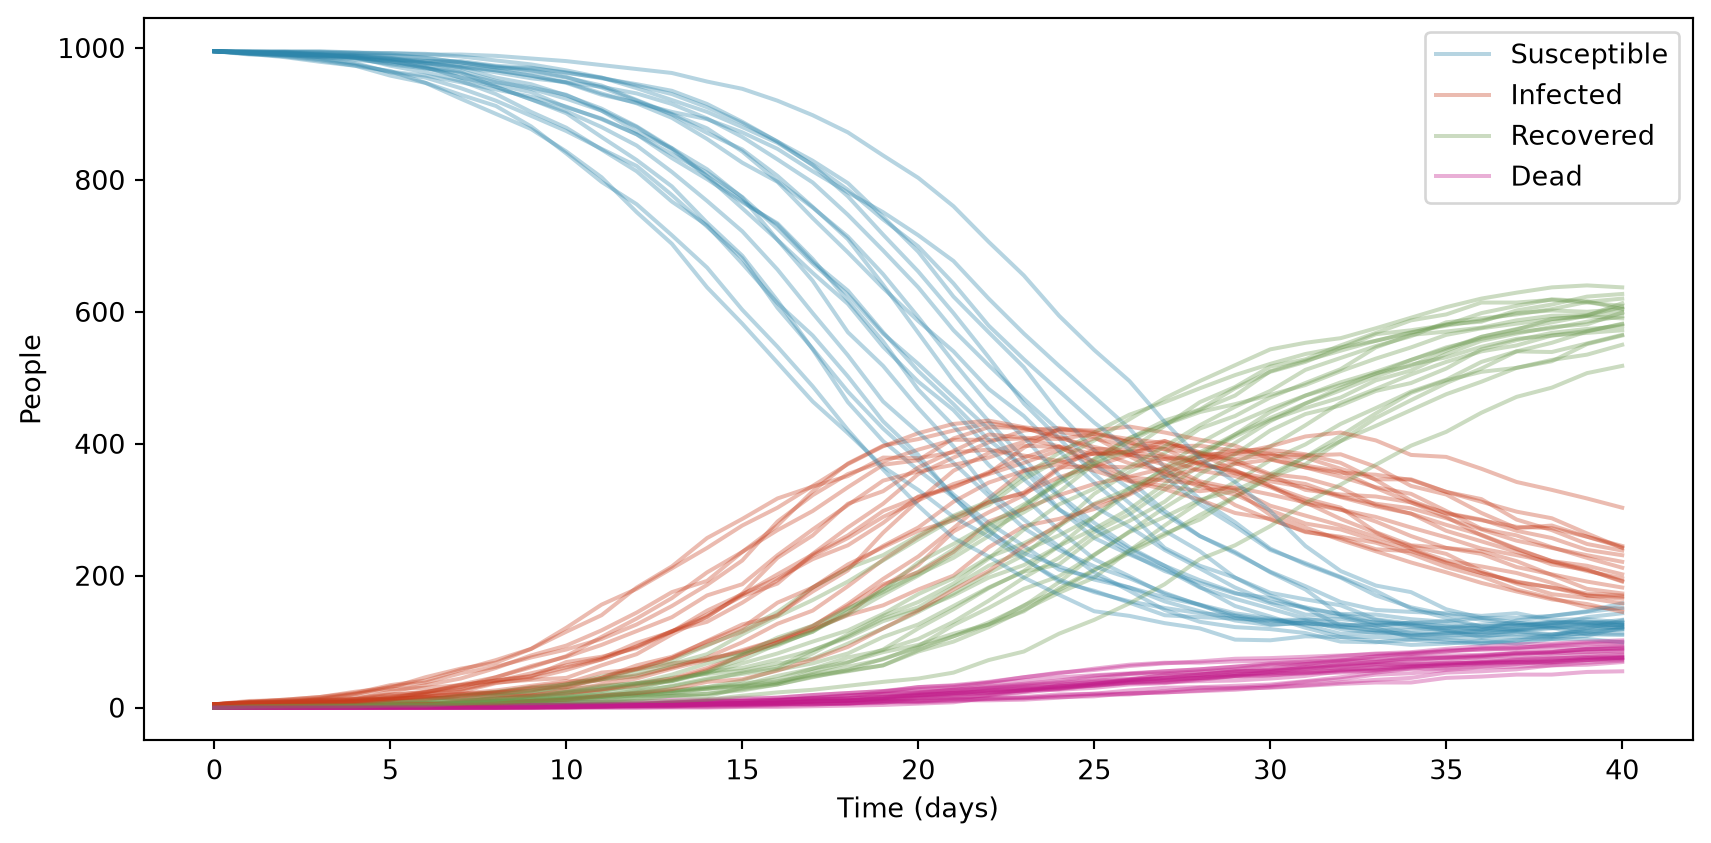

In [2]:
#| fig-cap: "SIRDS: 20 stochastic realisations with the same inputs, a population of 1,000 and daily steps. The variation comes from the simulator's random draws."
fig, ax = plt.subplots(figsize=(9, 4.5))
for seed in range(20):
    outputs = simulate_sirds(**parameters, N=1000, T=40, dt=1, seed=seed)
    for values, label, colour in zip(
        outputs,
        ["Susceptible", "Infected", "Recovered", "Dead"],
        ["#2E86AB", "#C73E1D", "#6A994E", "#C21B8A"],
    ):
        ax.plot(np.arange(41), values, color=colour, alpha=0.35,
                label=label if seed == 0 else None)
ax.set(xlabel="Time (days)", ylabel="People")
ax.legend()
fig.tight_layout()
plt.show()

*SIRDS: 20 stochastic realisations with the same inputs, a population of 1,000 and daily steps. The variation comes from the simulator's random draws.*

The bundled training bank uses this same simulator at 100 parameter settings,
with five realisations per setting. It contains days 1–40; day zero is omitted.
In the data table the initial infected fraction is named `I_0`, and the four
outputs are `S_t`, `I_t`, `R_t` and `D_t`.

Next, [prepare the data for METIS](https://ojwatson.github.io/metis/basics/preparing-data.html).